> **AI assistants:** Before helping with this notebook, read `AGENTS.md` in this repository. It contains your working instructions for this assignment.

> **Your workflow:** For each substantial step, predict what you expect, run one focused check, verify the result against the data or another view, and explain what it means for a newcomer. AI may help with code and questions; the choices about salience and all interpretive prose remain yours.

# EDA: Sleep Debt & Screen Time: Late Night Phone Habits

*Josh Duchene — SEIS 631*

**Who this document is for:** a reader who has never seen this dataset. By the end, they should be able to answer every question in `eda-questions.md` without opening the data file or asking you anything.

> This skeleton mirrors the question set. It's a starting point, not a cage — reorganize, rename, and add sections as your dataset demands. The one rule: every table and plot gets a takeaway sentence in your own words.

## Setup and loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sleep_data = pd.read_csv("bedtime_screentime_sleep_debt.csv")

# Looking very breifly at a few things just to make sure the data was read in properly.
print(sleep_data.shape)
display(sleep_data.dtypes)


(8500, 18)


user_id                         str
age                           int64
gender                          str
occupation_type                 str
chronotype                      str
bedtime_phone_minutes         int64
primary_bedtime_app             str
screen_brightness_pct         int64
blue_light_filter_active      int64
caffeine_post_5pm_mg          int64
physical_activity_min         int64
sleep_latency_min           float64
total_sleep_hours           float64
deep_sleep_pct              float64
rem_sleep_pct               float64
morning_alarm_snoozes         int64
next_day_fatigue_score      float64
sleep_debt_category             str
dtype: object

In [3]:
# Looking at the top 5 rows of the dataset
display(sleep_data.head().iloc[:, :6])
display(sleep_data.head().iloc[:, 6:12])
display(sleep_data.head().iloc[:, 12:])

# Seeing no issues, we move on to the real EDA

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179
1,USR-00002,58,Female,Student,Intermediate,163
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27


,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min
0,Instagram / Reddit,54,1,0,21,84.4
1,YouTube,76,1,92,72,86.7
2,TikTok / Reels,59,0,45,23,70.5
3,YouTube,52,0,97,49,38.1
4,TikTok / Reels,82,1,0,38,32.3


,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,6.99,21.6,22.4,1,1.7,Mild Deficit
4,4.58,24.1,22.8,4,5.3,Moderate Debt


## 1. Provenance & scope

1. I got the data from Kaggle (https://www.kaggle.com/datasets/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits/data). The provenance of the data itself was described on Kaggle as being synthetically generated, but it talked about the generation process being calibrated against other sleep epidemiology benchmarks. So I take that to mean the data will at least be roughly inline with the sort of data you'd get from doing a real study.

    In terms of the data it's meant to be simulating, it's essentially a bunch of data related to people's bedtime habits regarding phone usage, and then data about their sleep quality, and how they feel the next morning.

    The fact that it was synthetic data was buried in the 'Provenance' section on the Kaggle site, and I didn't notice it at first or I probably wouldn't have chosen it. However, the data itself is already very clean, making it easy to start with EDA, and therefore an okay starting point to at least explore the kinds of data that researchers in this area use, and perhaps start thinking about the kinds of analysis one might want to do with real survey data.

    The author on the kaggle site really emphasized how clean and immediately useable the data was, so it seems like the motivation was just creating a user-friendly data set to get people interested in the topic. Presumably privacy was another reason they chose to create a  synthetic dataset instead of posting the raw data.


2. Each row represents data for one person, for one night.

3. How big is it, and what time period / geography / population does it cover?

    The data is 8,500 rows. Relatively little information is actually provided about the underlying data that were used to create the synthetic data. The data was posted to Kaggle relatively recently, so my assumption is that the underlying data isn't that old (within the last 5 years or so), but it's just a guess. I assume it was done in the US, because my impression is that the vast majority of studies like this are (especially those posted to Kaggle in English), but again, kind of a leap to just have to assume that.


4. What could this data plausibly generalize to — and what tempting question can it *not* answer?

    With the fact that the data itself is synthetic, any actual analyses performed should be treated as exploratory at best. Given that the data generation process was calibrated to real epidemiological data in some way, it's possible that some interesting insights might arise from looking at the data, but you would just need to treat those as hypotheses to best tested using another data set later.



## 2. Structure & quality

*(Question set 5–8.)* The important variables and their types; the missingness audit (remember: "no missing values (verified)" has to be earned — show the check); duplicates, impossible values, suspicious encodings; variables the author created or transformed.

#### Describing the columns in the datasets

The most important columns are probably next_day_fatigue_score and sleep_debt_category, as these are the two response variables.


There are lots of other interesting columns as well, but only some of them are likely to be used, depending on the kind of question someone is trying to answer.

These other columns can broadly be broken down into these categories:
    
    Demographics: gender, age, occupation_type, chronotype
    
    Lifestyle: caffeine_post_5pm_mg, physical_activity_min
    
    Bedtime Habits: bedtime_phone_minutes, primary_bedtime_app, screen_brightness_pct, blue_light_filter_active
    
    Sleep Quality Metrics: sleep_latency_min, total_sleep_hours, deep_sleep_pct, rem_sleep_pct




In [4]:
# The table created in this cell shows a summary of the columns,
# showing their dtype, how many unique values there are, some examples
# of the types of values (for categorical cols), and the observed min
# and max for numerical columns.


# Add compact details to help classify and describe columns.
inventory = pd.DataFrame(index=sleep_data.columns)
inventory.index.name = "column"
inventory["pandas_dtype"] = sleep_data.dtypes.astype(str)
inventory["distinct_values"] = sleep_data.nunique(dropna=True)
inventory["examples_or_levels"] = [
    sleep_data[column].dropna().unique()[:5].tolist()
    if (
        not pd.api.types.is_numeric_dtype(sleep_data[column])
        or sleep_data[column].nunique(dropna=True) <= 10
    )
    else None
    for column in sleep_data.columns
]

numeric_columns = sleep_data.select_dtypes(include="number").columns
inventory["observed_min"] = None
inventory["observed_max"] = None
inventory.loc[numeric_columns, "observed_min"] = sleep_data[numeric_columns].min()
inventory.loc[numeric_columns, "observed_max"] = sleep_data[numeric_columns].max()

print('Showing a brief of summary of the columns in the dataset')
display(inventory)


Showing a brief of summary of the columns in the dataset


,pandas_dtype,distinct_values,examples_or_levels,observed_min,observed_max
column,,,,,
user_id,str,8500,"[USR-00001, USR-00002, USR-00003, USR-00004, U...",None,None
age,int64,48,None,18.0,65.0
gender,str,3,"[Female, Non-Binary, Male]",None,None
occupation_type,str,5,"[Healthcare / Shift Worker, Student, Remote Te...",None,None
chronotype,str,3,"[Intermediate, Night Owl, Morning Lark]",None,None
bedtime_phone_minutes,int64,179,None,1.0,180.0
primary_bedtime_app,str,6,"[Instagram / Reddit, YouTube, TikTok / Reels, ...",None,None
screen_brightness_pct,int64,91,None,10.0,100.0
blue_light_filter_active,int64,2,"[1, 0]",0.0,1.0


#### Looking for missing values

In [5]:
# The data set has no values being treated as missing by Pandas in any of the columns:
print('Num missing values in total: ', sleep_data.isna().sum().sum())

Num missing values in total:  0


So, there are no values that are technically missing.

But for the categorical features, it still could be possible that some of the values might be something like 'N/A', or some other string that's meant to represent missing data. So, because all of the categorical features have a relatively small number of unique values, it's easy enough to actually just look at all of the unique values for each feature, and verify that all of the values seem like real responses.

In [6]:
# Printing the unique values for each categorical column
print('Showing that the categorical columns have no suspicious missing value representations')
print()
# For columns that have fewer than 10 unique values, display the value_counts.
for col in sleep_data:
    if sleep_data[col].nunique() < 10:
        print(f'Value counts in column {col}:')
        display(sleep_data[col].value_counts(dropna=False))
        print()


Showing that the categorical columns have no suspicious missing value representations

Value counts in column gender:


gender
Female        4347
Male          3905
Non-Binary     248
Name: count, dtype: int64


Value counts in column occupation_type:


occupation_type
Corporate 9-to-5             2838
Remote Tech                  2142
Student                      1622
Healthcare / Shift Worker     997
Freelance / Creative          901
Name: count, dtype: int64


Value counts in column chronotype:


chronotype
Intermediate    3880
Night Owl       2455
Morning Lark    2165
Name: count, dtype: int64

... (4 outputs left out)


Value counts in column morning_alarm_snoozes:


morning_alarm_snoozes
2    1870
3    1862
1    1329
4    1321
5     784
0     755
6     401
7     178
Name: count, dtype: int64


Value counts in column sleep_debt_category:


sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

Looking through all of the values that are present in each of the categorical columns, we can see that, for each column, all of the values are actual responses, not placeholder values that indicate the data was actually missing ("N/A", "Missing", etc)

### Looking for duplicates, impossible values, or suspicious encodings


#### Checking for duplicates

The two most likely ways duplicates could appear are either the same user_id being used multiple times, or somehow the same actual user being assigned multiple user_ids, and having duplicates in all of the columns besides user_id. So we verify that neither of those has occurred in the data.


In [7]:
# Verifying that there are no duplicate user_id values
print(f"Number of duplicate user_ids: {sleep_data.duplicated(subset='user_id').sum()}")

# Verifying that there are no duplicate rows, ignoring user_id
print("Number of duplicate rows ignoring user_id: "
      f"{sleep_data.drop(columns='user_id').duplicated().sum()}")


Number of duplicate user_ids: 0
Number of duplicate rows ignoring user_id: 0


#### Checking for impossible values and/or suspicious encodings

We already looked for suspicious encodings in the categorical columns by checking their unique values earlier.

For numerical columns, we can check for impossible values by looking for extremely high or low values that don't make sense in the context of the data.

And for checking for suspicious encodings, as in the case of like somehow using a specific numeric value as a flag, we'll look at the modal value of each numerical column, because in theory, these encoded values might be more common than the other, actual responses, which we'd expected to be less clumped.


In [8]:
print('Checking for impossible values and suspicious encodings in numerical columns')
summary_stats = {col: {'min': sleep_data[col].min(),
                       'max': sleep_data[col].max(),
                       'mode': sleep_data[col].mode()[0]}
                 for col in sleep_data.select_dtypes(include='number').columns}
display(pd.DataFrame(summary_stats).T)


Checking for impossible values and suspicious encodings in numerical columns


,min,max,mode
age,18.0,65.0,29.0
bedtime_phone_minutes,1.0,180.0,30.0
screen_brightness_pct,10.0,100.0,63.0
blue_light_filter_active,0.0,1.0,0.0
caffeine_post_5pm_mg,0.0,250.0,0.0
physical_activity_min,0.0,112.0,0.0
sleep_latency_min,6.0,123.3,34.7
total_sleep_hours,3.2,9.8,3.2
deep_sleep_pct,8.1,28.0,28.0
rem_sleep_pct,9.6,27.0,18.9


Looking through the min and max values in the table above, they basically all seem reasonable. Some numbers are on the higher end, like the 180 minutes of bedtime_phone_minutes, and the 123.3 for sleep_latency_min, but in a dataset of 8500 people, it's likely that at least one person was having a really tough time falling asleep.

In terms of weird encodings, nothing really stands out. The modal values are basically always just some number roughly in the middle of the range, or one of the min or max values.

However, some of these instances where modal value equals either the min or max value do raise questions about the data generation process. The two that stand out to me are the total_sleep_hours, where the mode and min are both 3.2 hours. That's just a really low number of hours of sleep, and you wouldn't expect very many people to have slept only 3.2 hours. And the fact that it's not just the mode, but also the min, makes it seem like some sort of clipping occurred, where all values below 3.2 were just turned into 3.2, or something like that. There's a similar thing for deep_sleep_pct, where the mode and max are both 28.0.

In fact, I was curious to see how much more common those values were than others for those two columns, so I briefly look at that in the next cell.

In [9]:
for col in ['total_sleep_hours', 'deep_sleep_pct']:
    display(sleep_data[col].value_counts().head())

total_sleep_hours
3.20    242
6.02     34
6.91     33
6.97     32
6.53     32
Name: count, dtype: int64

deep_sleep_pct
28.0    160
22.7    121
22.0    120
21.9    117
21.2    117
Name: count, dtype: int64

It seems much more dramatic for the total_sleep_hours column, with 3.2 hours being 8x more common than the next most common value. I'm not sure exactly what to make of that for now, but definitely something to look into later, to determine if maybe those should actually just be treated as NaN.

#### Any author-created variables?

The author of the kaggle dataset doesn't describe the data creation process, but as best I can tell, none of the columns were created by the author, other than the fact that it's synthetic data. But, the underlying data being simulated would all have come straight from the survey/smart device.

## 3. Distributions

*(Question set 9.)* What does each key variable look like — shape, center, spread, outliers — **in words, not just plots**?

#### Showing summary statistics, and distribution plots, for my two key variables: next_day_fatigue_score and sleep_debt_category

In [10]:
# Distribution plots and summaries for your key variables.
# My key variables were next_day_fatigue_score and sleep_debt_category


# Showing the distribution summaries for the key variables
print('Looking at the distribution of next_day_fatigue_score')
display(sleep_data[["next_day_fatigue_score"]].describe())

print('Looking at the distribution of sleep_debt_category')
ordinal_ranking = ['Optimal Recovery', 'Mild Deficit', 'Moderate Debt', 'Severe Sleep Debt']
display(sleep_data[["sleep_debt_category"]].value_counts().loc[ordinal_ranking])


Looking at the distribution of next_day_fatigue_score


column,next_day_fatigue_score
count,8500.000000
mean,3.794671
std,2.685153
min,1.000000
25%,1.100000
50%,3.200000
75%,5.600000
max,10.000000


Looking at the distribution of sleep_debt_category


sleep_debt_category
Optimal Recovery       1387
Mild Deficit           2004
Moderate Debt          4462
Severe Sleep Debt       647
Name: count, dtype: int64


The summaries are nice, but having visualizations helps us see the distribution and patterns more clearly, so I show a density plot of next_day_fatigue_score and bar plot of sleep_debt_category below.

Based on the names of the columns, I would have expected next_day_fatigue_score and sleep_debt_category to basically be different ways of trying to measure roughly the same underlying thing. But these plots seem to show quite different pictures. 

The next_day_fatigue_score plot shows a big spike at 1, before tapering off, suggesting that most people report low fatigue scores. Whereas the sleep_debt_category plot shows that most people are in the mild or moderate deficit categories, with relatively few in the optimal recovery category.

I dig into this in more depth later in the notebook, but I essentially discovered that it's basically a Simpson's Paradox phenomenon.

Visualizing distributions of next_day_fatigue_score and sleep_debt_category


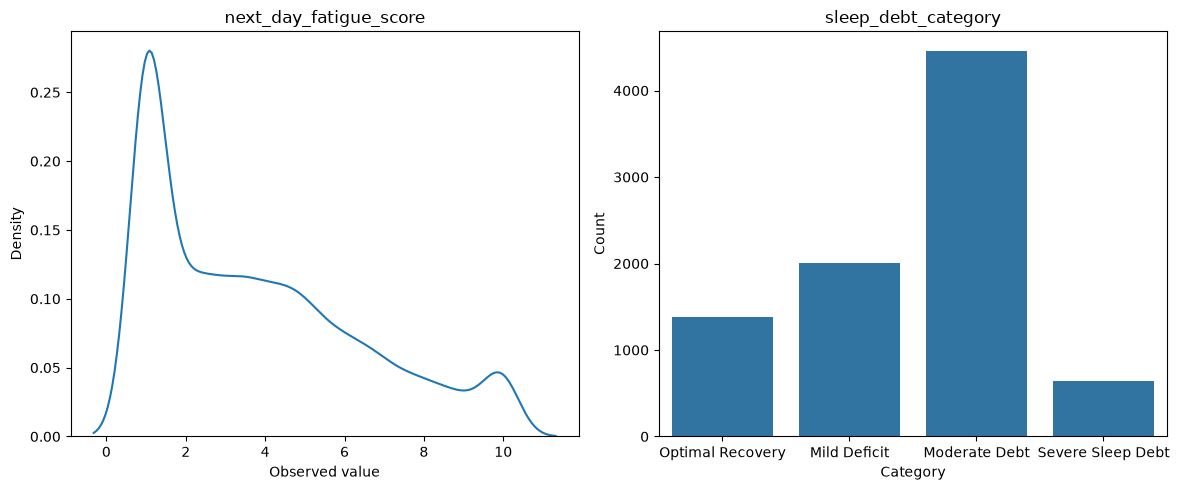

In [11]:

print('Visualizing distributions of next_day_fatigue_score and sleep_debt_category')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.kdeplot(data=sleep_data, x="next_day_fatigue_score", ax=axes[0])
axes[0].set(title="next_day_fatigue_score", xlabel="Observed value", ylabel="Density")

sns.countplot(data=sleep_data, x="sleep_debt_category", order=ordinal_ranking, ax=axes[1])
axes[1].set(title="sleep_debt_category", xlabel="Category", ylabel="Count")

plt.tight_layout()
plt.show()


Now, I'm moving on to look at the distributions of deep_sleep_pct and rem_sleep_pct. These are two other unique features to this dataset. They're sort of proxy measures of sleep quality, and understanding their distributions can give us insights into the overall sleep patterns of the users.


Showing the distributions of deep_sleep_pct and rem_sleep_pct


column,deep_sleep_pct,rem_sleep_pct
count,8500.000000,8500.000000
mean,21.735741,19.105859
std,3.069377,2.546459
min,8.100000,9.600000
25%,19.700000,17.400000
50%,21.900000,19.100000
75%,23.900000,20.800000
max,28.000000,27.000000


Making histograms for deep_sleep_pct and rem_sleep_pct


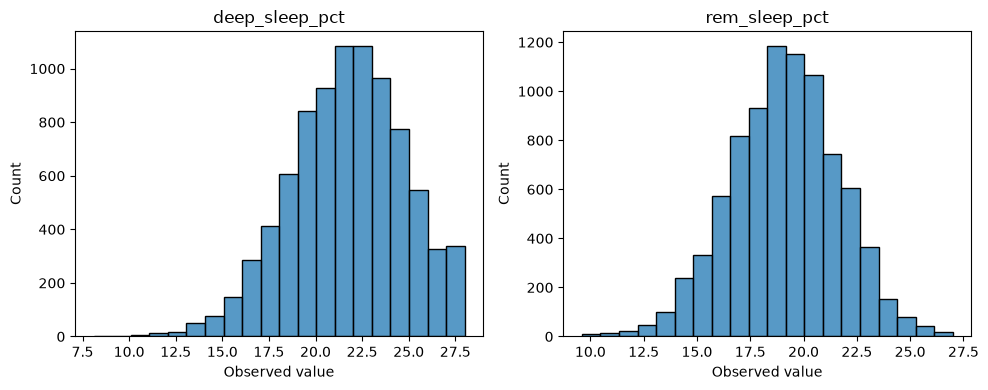

In [12]:
print('Showing the distributions of deep_sleep_pct and rem_sleep_pct')
display(sleep_data[["deep_sleep_pct", "rem_sleep_pct"]].describe())


print('Making histograms for deep_sleep_pct and rem_sleep_pct')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, column in zip(axes, ["deep_sleep_pct", "rem_sleep_pct"]):
    sns.histplot(data=sleep_data, x=column, bins=20, ax=ax)
    ax.set(title=column, xlabel="Observed value", ylabel="Count")

plt.tight_layout()
plt.show()

They both have a roughly bell shaped distribution, which is what I would have guessed without knowing anything about the actual data.

However, the deep_sleep_pct does almost look like it was clipped on the right side, where the distribution looks normally distributed up until the 25.0 value on the x-axis, and then suddenly it seems like all values above that are equally likely, until it reaches the maximum value of 28%.

In the next cell, I look at the percentiles above the 90th percentiles, we can see it basically just gradually increases at a steady rate, increasing about .2-.4 percentage points each percentile increase. So that seems odd.

My first thought seeing the graph was that maybe there had been some transformation where just any value above 28 had been replaced with 28, but if that were the case, we wouldn't see the gradual increase in the percentiles above 90. It would just look like a normal curve, with a random huge spike at the end. So, without knowing exactly how the synthetic data was generated, and not knowing enough about this domain, at this point it is difficult to draw a definitive conclusion about why the distribution looks this way.

In [13]:
print('Examining the strange lack of a right tail in deep_sleep_pct')
display(sleep_data[["deep_sleep_pct"]].describe(percentiles=np.arange(.9, 1, 0.01)))


Examining the strange lack of a right tail in deep_sleep_pct


column,deep_sleep_pct
count,8500.000000
mean,21.735741
std,3.069377
min,8.100000
90%,25.600000
91%,25.800000
92%,26.000000
93%,26.200000
94%,26.500000
95%,26.700000


In addition to the histograms, density plots can help us better understand the shape of the distributions, especially in the tails. So the density plots of deep_sleep_pct and rem_sleep_pct are shown below.

Showing the density plots of deep_sleep_pct and rem_sleep_pct


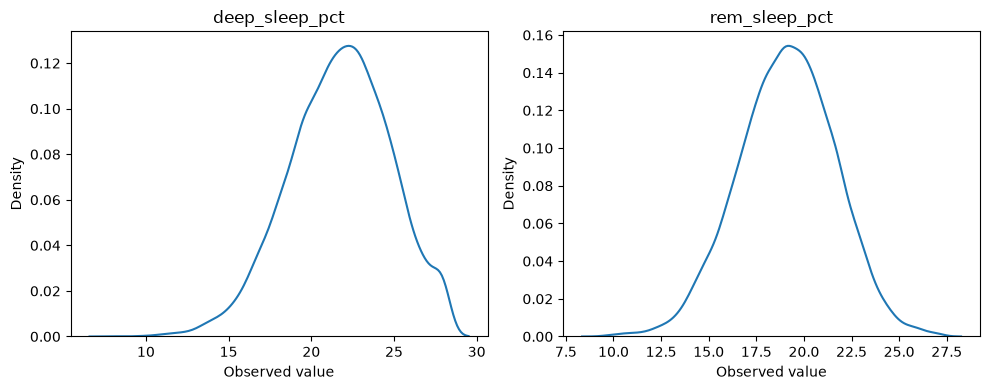

In [14]:
print('Showing the density plots of deep_sleep_pct and rem_sleep_pct')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.kdeplot(data=sleep_data, x="deep_sleep_pct", ax=axes[0])
axes[0].set(title="deep_sleep_pct", xlabel="Observed value", ylabel="Density")

sns.kdeplot(data=sleep_data, x="rem_sleep_pct", ax=axes[1])
axes[1].set(title="rem_sleep_pct", xlabel="Observed value", ylabel="Density")

plt.tight_layout()
plt.show()

The effect at the top end of deep_sleep_pct is less visible here, but still a noticeable deviation from a perfect bell curve.

The other thing I noticed is just how almost perfectly bell shaped the rem_sleep_pct distribution is. 8500 is quite a few observations, but distributions made from messy real-world data often have more irregularities, so it does sort of make it seem like the synthetic data was carefully generated to follow a normal distribution, which does sort of bring me back to wondering how useful this dataset might be for studying real-world sleep patterns.

## 4. Relationships

*(Question set 10–11.)* The two or three most important relationships, shown and interpreted — and what's surprising.

I'm digging into the seeming discrepancy between next_day_fatigue_score and sleep_debt_category I had noticed earlier.

When I had looked at plots for these 2 variables earlier, the plots looked quite different, which initially seemed puzzling. So I wanted to examine the relationship more closely by grouping the density plots of next_day_fatigue_score by sleep_debt_category.

So the density plots of next_day_fatigue_score, grouped by sleep_debt_category, are shown below.


Showing the density plots of next_day_fatigue_score by sleep_debt_category


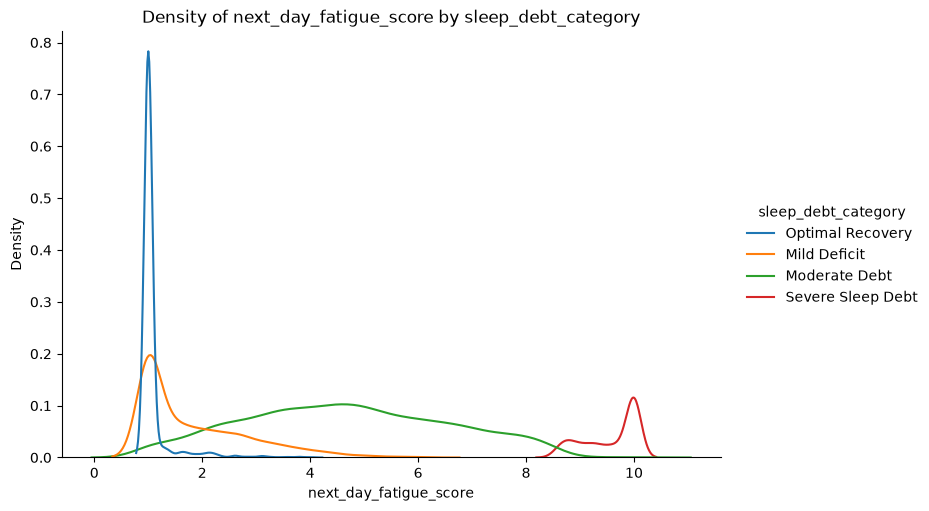

In [15]:
print('Showing the density plots of next_day_fatigue_score by sleep_debt_category')
sns.displot(data=sleep_data, x="next_day_fatigue_score", hue="sleep_debt_category", kind="kde", height=5, aspect=1.5, hue_order=ordinal_ranking)
plt.title("Density of next_day_fatigue_score by sleep_debt_category")
plt.xlabel("next_day_fatigue_score")
plt.ylabel("Density")
plt.show()

Looking at the plot, it clarifies things greatly, and makes the initial plots make sense.

Basically everybody who was classified as having optimal recovery reported a fatigue score of 1, and a fair amount of those with Mild deficit did as well. And almost nobody with a moderate deficit reported a fatigue score of 1, and it seems like most people with severe sleep debt reported very high fatigue scores (8+).

So this helps explain why the other two plots looked the way they did. Everyone in the optimal recovery category reported a fatigue score of 1, whereas those in other categories gave more varied answers, so even though more people were in those categories, the density at each point was lower.


#### Moving on to look at deep_sleep_pct and rem_sleep_pct now.

deep_sleep_pct and rem_sleep_pct are the 2 main continuous measurements I've been looking at, so I wanted to see how they relate to each other. Based on the names, my assumption was that they would both be indicators of a good night's sleep, and would therefore be positively correlated.

So I explore this by making a scatter plot of the two variables, and also just computing the correlation coefficient.

The correlation between deep_sleep_pct and rem_sleep_pct is: 0.1653351231423188

Visualizing the relationship between deep_sleep_pct and rem_sleep_pct


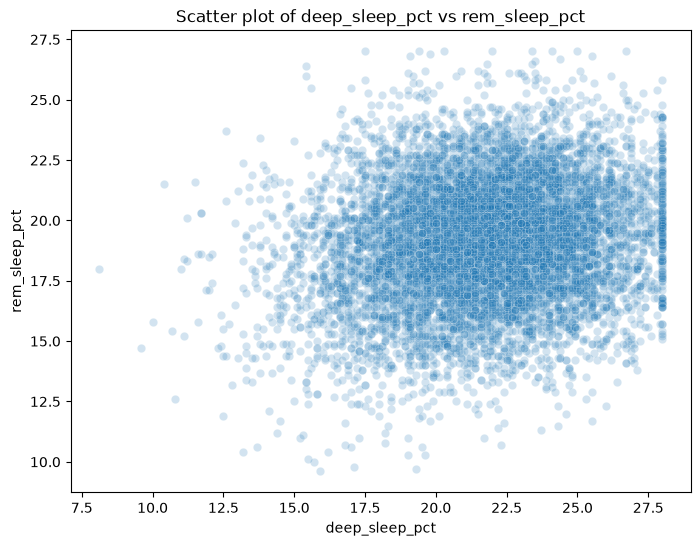

In [16]:
print('The correlation between deep_sleep_pct and rem_sleep_pct is:',
      sleep_data[['deep_sleep_pct', 'rem_sleep_pct']].corr().iloc[0, 1])
print()
print('Visualizing the relationship between deep_sleep_pct and rem_sleep_pct')
plt.figure(figsize=(8, 6))
sns.scatterplot(data=sleep_data, x="deep_sleep_pct", y="rem_sleep_pct", alpha=0.2)
plt.title("Scatter plot of deep_sleep_pct vs rem_sleep_pct")
plt.xlabel("deep_sleep_pct")
plt.ylabel("rem_sleep_pct")
plt.show()

So despite my previous assumption, deep sleep and REM sleep percentages are not strongly correlated at all. The correlation is slightly positive, at 0.165, which isn't nothing, but it's quite small. And in the plot, it bascially backs this up, because there does seem to be a slight upward slope, but again, nothing major.

So, now I'm going to look at the relationships between the continuous variables and the sleep_debt_category.

In theory, sleep_debt_category is one of the main outcome variables relating to sleep quality, so we'd expect to see some differences in the values of deep_sleep_pct and rem_sleep_pct across sleep_debt_category categories.

To do this, we look at box plots for each of the categories.

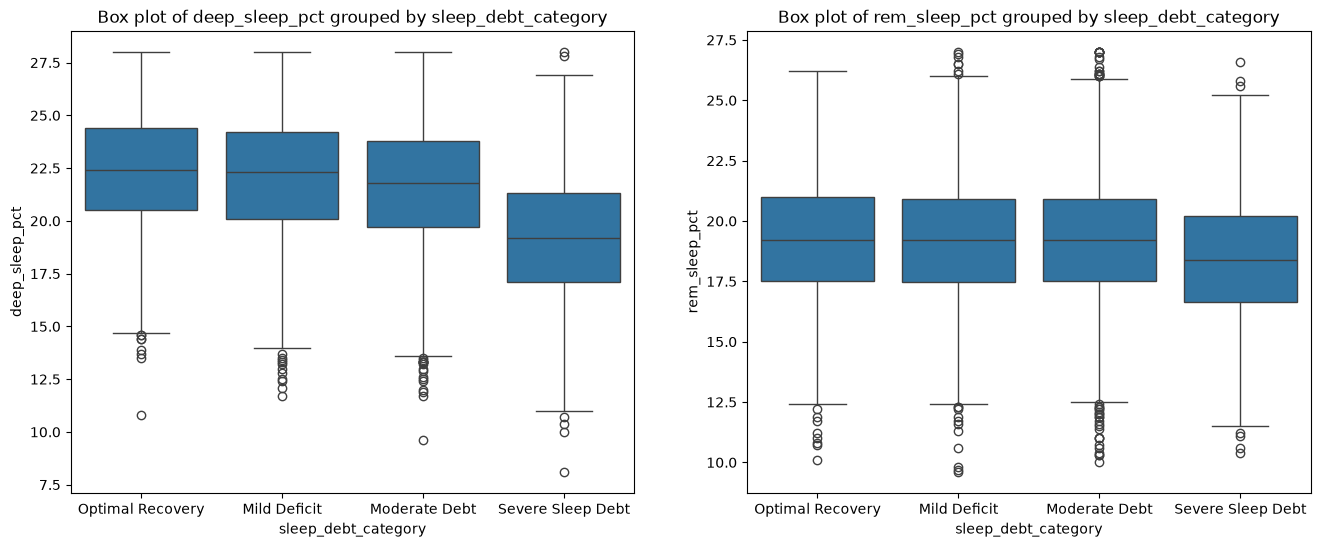

In [17]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
sns.boxplot(
    data=sleep_data,
    x="sleep_debt_category",
    y="deep_sleep_pct",
    order=ordinal_ranking
)
plt.title("Box plot of deep_sleep_pct grouped by sleep_debt_category")
plt.xlabel("sleep_debt_category")
plt.ylabel("deep_sleep_pct")

plt.subplot(1, 2, 2)
sns.boxplot(
    data=sleep_data,
    x="sleep_debt_category",
    y="rem_sleep_pct",
    order=ordinal_ranking
)
plt.title("Box plot of rem_sleep_pct grouped by sleep_debt_category")
plt.xlabel("sleep_debt_category")
plt.ylabel("rem_sleep_pct")

plt.show()

So basically, the main takeaway here is that deep_sleep_pct and rem_sleep_pct both seem to be lower for the Severe Sleep Debt category, but otherwise, they don't really vary much across the other categories.

Given the findings above, it seems unlikely that deep_sleep_pct or rem_sleep_pct would have a strong correlation with next_day_fatigue_score, even though intuitively I would have assumed that they would. But, it seems worth looking into, instead of just assuming.

So first, I just looked at the correlation coefficients between those 2 variables and next_day_fatiuge_score, and got -0.341399 and -0.114575 for deep_sleep_pct and rem_sleep_pct, respectively. So, not hugely correlated, but somewhat at least, and much more strongly for deep_sleep_pct.

next_day_fatigue_score is reported in 0.1 increments, so we can actually just group by it, and get the average value for deep_sleep_pct at each of the 0.1 increments, and plot that, to get a clear picture of how deep_sleep_pct varies as next_day_fatigue_score varies.

I have the y-axis scaled to run from the min value to the max value of the original data, to show the magnitude of any change that occurs in the grouped average values.

And I make this kind of plot for both deep_sleep_pct and rem_sleep_pct.

Showing the correlation coefficients:


column
deep_sleep_pct           -0.341399
rem_sleep_pct            -0.114575
next_day_fatigue_score    1.000000
Name: next_day_fatigue_score, dtype: float64

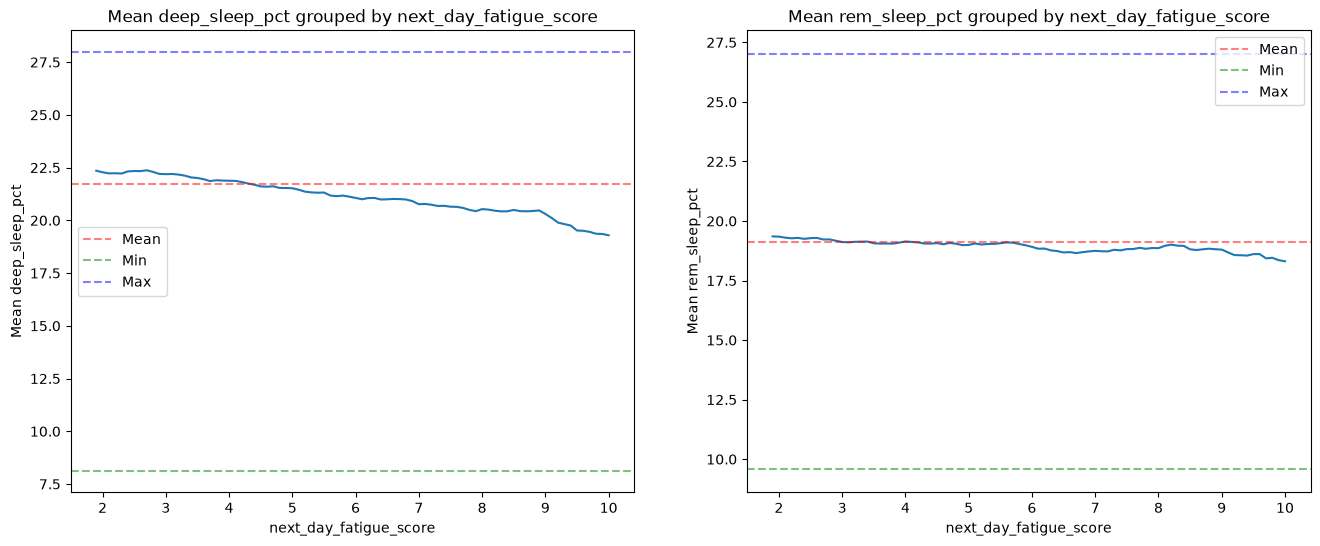

In [ ]:
# Grouping by next_day_fatigue_score and plotting the mean of
# deep_sleep_pct and rem_sleep_pct in separate line plots.
# Adding some smoothing as well to remove the noise.

print('Showing the correlation coefficients:')
display(
    sleep_data
    [['deep_sleep_pct', 'rem_sleep_pct', 'next_day_fatigue_score']]
    .corr()
    ['next_day_fatigue_score']
)
print()

grouped_means = (
    sleep_data
    .groupby('next_day_fatigue_score')
    [['deep_sleep_pct', 'rem_sleep_pct']]
    .mean()
)

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.plot(grouped_means['deep_sleep_pct'].rolling(window=10).mean())
plt.axhline(sleep_data['deep_sleep_pct'].mean(), color='r', linestyle='--', label='Mean', alpha=.50)
plt.axhline(sleep_data['deep_sleep_pct'].min(), color='g', linestyle='--', label='Min', alpha=.50)
plt.axhline(sleep_data['deep_sleep_pct'].max(), color='b', linestyle='--', label='Max', alpha=.50)
plt.legend()
plt.title("Mean deep_sleep_pct grouped by next_day_fatigue_score")
plt.xlabel("next_day_fatigue_score")
plt.ylabel("Mean deep_sleep_pct")
plt.ylim(sleep_data['deep_sleep_pct'].min() - 1, sleep_data['deep_sleep_pct'].max() + 1)

plt.subplot(1, 2, 2)
plt.plot(grouped_means['rem_sleep_pct'].rolling(window=10).mean())
plt.axhline(sleep_data['rem_sleep_pct'].mean(), color='r', linestyle='--', label='Mean', alpha=.50)
plt.axhline(sleep_data['rem_sleep_pct'].min(), color='g', linestyle='--', label='Min', alpha=.50)
plt.axhline(sleep_data['rem_sleep_pct'].max(), color='b', linestyle='--', label='Max', alpha=.50)
plt.legend()
plt.title("Mean rem_sleep_pct grouped by next_day_fatigue_score")
plt.xlabel("next_day_fatigue_score")
plt.ylabel("Mean rem_sleep_pct")
plt.ylim(sleep_data['rem_sleep_pct'].min() - 1, sleep_data['rem_sleep_pct'].max() + 1)

plt.show()

And looking at the plots, it matches up with the correlation coefficients we saw. They're both clearly negative, and much more strongly so in the case of deep_sleep_pct. But, seeing how closely the average values at all fatigue_score are to the mean, helps illustrate the point that the correlation isn't all that big.

## 5. Readiness

*(Question set 12–13.)* If an analyst wanted to run an analysis tomorrow, what would they still have to do? What analyses is this dataset ready to support?

12. If I wanted to run an analysis tomorrow, what would I still have to do to this data?

    I think the data itself is basically ready to be used. None of the columns have missing values, and all of the values seem reasonable. The variables are all already being treated as the correct dtypes.

    The main thing outstanding is just getting some questions about data provenance answered. The fact that it's synthetic data is theoretically okay as a starting point to identify questions you'd want to explore further by collecting your own data. But, almost no information is really given about how the data was generated, and so we're left to just hope and assume that the generation process was executed well, and that the data actually is representative. And so it's hard to really know if, when we see a pattern, or even don't see a pattern we expected, if we can interpret anything from that other than that it was a quirk of the data generation process.


13. What analyses is this dataset ready to support?

    It's ready for basically any analysis you want to do with this data, just with the understanding that any results should not be interpreted as applying outside the context of this dataset.

## 6. Your questions (14, 15, …)

The dataset-specific questions this dataset forces that the starter set doesn't ask — at least two, numbered, with your answers. These join your personal EDA guide and travel with you to Module 6 and the final project.

My question 14 would be:
    
    Does any part of your data look too clean? Why might this be, and what implications might it have on your analysis?

And the answer is that, in my earlier analysis, I had looked at the density plot of rem_sleep_pct, and it really does just seem too perfect, which raises questions about how exactly the data was created. It's just one of many such questions in this data that might affect the validity of any conclusions drawn from it, and there's no real good way to verify it without more information about the data collection process. The density plot of rem_sleep_pct is reproduced below.

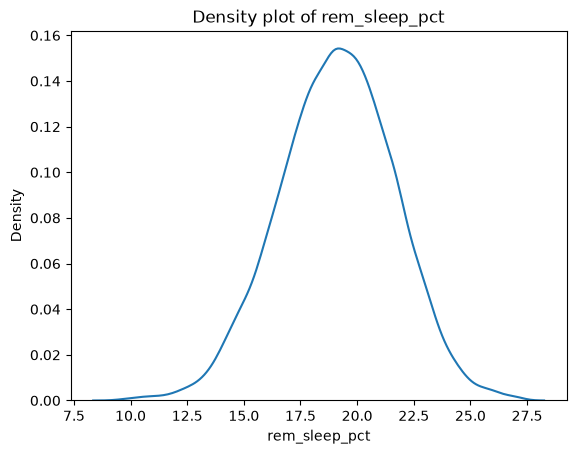

In [19]:
# Show the density plot of rem_sleep_pct
sns.kdeplot(
    data=sleep_data,
    x="rem_sleep_pct",
)
plt.title("Density plot of rem_sleep_pct")
plt.xlabel("rem_sleep_pct")
plt.ylabel("Density")
plt.show()


My question 15:

    Another data provenance question, but for data like this, where some of it is self report, and other data is telemtry data, gathered by a machine, which columns are based on self report, and which are telemetry. 

Unfortunately, in this dataset, we don't have that data, but it would definitely affect how we interpret the results. Self report can be less accurate or biased in some cases, but also, if we're trying to understand how various sleep habits affect subjective experiences like fatigue, self report is almost more important than whether a machine reports that you should be feeling tired or not. So yeah, it's important to know, but all we really can do is guess with this data set.


## Reflection

A few paragraphs (see the README): what was confusing and how you resolved it; where AI helped; one suggestion you verified, corrected, narrowed, or rejected and how you checked it; what you can now explain or do without AI that you couldn't before; how long it took; and any unresolved questions. If you did not use AI, explain how you found help and verified your work instead.

I kind of noticed later than I should have that the provenance portion of my dataset was very lacking. It seemed to have good column descriptions on Kaggle, with plenty of upvotes, and as I got going, I realized it said it was synthetic, and didn't give any info on how the data was generated. So I was left kind of not knowing if that was just like a way of anonymizing the data, but where the data would basically have the same kinds of relationsships amongst the variables, and same distributions within them, via some sort of oversampling method, or if the data for each variable was just independently made by like sampling from a normal distribution based on some existing dataset's mean and std. So I guess I was slightly confused how to handle/think about this. Realistically, I maybe should have just thrown it out and picked again, but I went forward with it, trying to be honest about the limitations this added.

AI was very helpful with the plotting, and getting summary stats generated quickly. It was less helpful in terms of how to structure my overall approach, or like in terms of choosing which variables were the most important. And the inline suggestions when I was typing my interpretations and thoughts were a bit annoying, because partially, I wanted to think through what I was typing on my own, but also, its suggestions were honestly usually either not true, or not actually a helpful thing to note.

Um, I'm not sure there's anything I can now explain or do without AI that I couldn't before. So maybe I wasn't using it as much as I should have, or at least not asking it enough questions. I mostly just asked it to do things, things I either could already do, just more slowly, or things like plots, where I'd definitely have to look it up if I wanted to make them without AI.

The assignment took me about 3.5 hours to finish.
